# 06. 데이터 전처리 ① 데이터 탐색과 결측치 처리

**AICE Associate 학습 6단계**

시험의 **데이터 전처리 영역(30점)** 에서는 거의 매번 **이상치 처리 → 결측치 처리 → 인코딩 → 데이터 분리 → 스케일링** 순서로 문항이 나옵니다.
이번 노트북은 그중 **데이터 탐색(EDA)** 과 **결측치 처리**를 다룹니다.

### 학습 목표
1. 데이터의 구조·통계·분포를 빠르게 파악한다.
2. 결측치를 찾고 개수와 비율을 계산한다.
3. 결측치를 삭제(`dropna`)하거나 대체(`fillna`, `SimpleImputer`)하는 방법과 기준을 익힌다.

### 사용 데이터: `sc_cust_info_txn_v1.5.csv`
| 컬럼 | 설명 |
|---|---|
| cust_class | 고객 등급 |
| sex_type | 성별 |
| age | 나이 |
| efct_svc_count | 유효 서비스 수 |
| dt_stop_yn | 일시정지 여부 |
| npay_yn | 미납 여부 |
| r3m_avg_bill_amt | 최근 3개월 평균 청구액 |
| r3m_A_avg_arpu_amt | 최근 3개월 A상품 ARPU |
| r3m_B_avg_arpu_amt | 최근 3개월 B상품 ARPU |
| termination_yn | 해지 여부 ← 예측 대상 |

> **다음 문항을 풀기 전에 <span style="color:red">아래 코드를 실행하세요.</span>** (시험에서 제공되는 라이브러리·한글폰트 설정 셀과 같은 형태)

In [1]:
import platform
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')

# OS에 따라서 한글 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    font_names = [f.name for f in fm.fontManager.ttflist]
    for cand in ['NanumGothicCoding', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
        if cand in font_names:
            plt.rc('font', family=cand)
            break
    print("(리눅스) 한글폰트 로드 완료")
elif os_name == 'Windows':
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")
elif os_name == 'Darwin':
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")
else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(리눅스) 한글폰트 로드 완료


---
## 1. 데이터 읽기와 구조 파악

In [2]:
df = pd.read_csv('sc_cust_info_txn_v1.5.csv')
print(df.shape)
df.head()

(9930, 10)


,cust_class,sex_type,age,efct_svc_count,dt_stop_yn,npay_yn,r3m_avg_bill_amt,r3m_A_avg_arpu_amt,r3m_B_avg_arpu_amt,termination_yn
0,B,F,61.0,2,N,N,7426.72,3434.29,2846.25,N
1,E,M,55.0,1,N,Y,23914.03,24911.58,656.88,N
2,D,M,NaN,4,N,Y,24819.29,18877.02,4975.65,N
3,C,M,52.0,1,Y,N,16411.67,15702.04,0.00,Y
4,C,M,22.0,2,N,N,9800.36,8108.21,1062.61,N


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9930 entries, 0 to 9929
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cust_class          9780 non-null   object 
 1   sex_type            9835 non-null   object 
 2   age                 9411 non-null   float64
 3   efct_svc_count      9930 non-null   int64  
 4   dt_stop_yn          9930 non-null   object 
 5   npay_yn             9930 non-null   object 
 6   r3m_avg_bill_amt    9621 non-null   float64
 7   r3m_A_avg_arpu_amt  9520 non-null   float64
 8   r3m_B_avg_arpu_amt  9930 non-null   float64
 9   termination_yn      9930 non-null   object 
dtypes: float64(4), int64(1), object(5)
memory usage: 775.9+ KB


In [4]:
df.describe()

,age,efct_svc_count,r3m_avg_bill_amt,r3m_A_avg_arpu_amt,r3m_B_avg_arpu_amt
count,9411.000000,9930.000000,9.621000e+03,9520.000000,9930.000000
mean,45.374030,2.004028,2.427841e+04,17809.076739,3121.739137
std,19.078782,2.417744,5.281436e+04,8945.077969,3651.645611
min,0.000000,1.000000,9.561000e+02,232.950000,0.000000
25%,36.000000,1.000000,1.411977e+04,11420.732500,0.000000
50%,45.000000,2.000000,1.960624e+04,16363.540000,2067.735000
75%,54.000000,2.000000,2.642811e+04,22452.417500,4800.190000
max,999.000000,60.000000,1.199481e+06,76791.200000,35582.790000


> 🔍 **describe 결과 읽는 법**
> - `count`가 컬럼마다 다르면 → 결측치 존재
> - `min`/`max`가 상식 밖이면 → 이상치 의심 (나이 0세, 999세 / 서비스 수 60개 등)
> - `mean`과 `50%`(중앙값)의 차이가 크면 → 분포가 한쪽으로 치우침(skewed)

In [5]:
df.describe(include='object')

,cust_class,sex_type,dt_stop_yn,npay_yn,termination_yn
count,9780,9835,9930,9930,9930
unique,8,2,2,2,2
top,D,M,N,N,N
freq,2138,5473,9117,8420,8116


In [6]:
for col in df.select_dtypes(include='object').columns:
    print(col, df[col].unique())

cust_class ['B' 'E' 'D' 'C' 'F' 'G' 'H' 'A' nan]
sex_type ['F' 'M' nan]
dt_stop_yn ['N' 'Y']
npay_yn ['N' 'Y']
termination_yn ['N' 'Y']


---
## 2. 결측치 탐색

| 코드 | 의미 |
|---|---|
| `df.isnull()` / `df.isna()` | 결측이면 True |
| `df.isnull().sum()` | 컬럼별 결측 개수 |
| `df.isnull().sum().sum()` | 전체 결측 개수 |
| `df.isnull().mean()` | 컬럼별 결측 비율 |
| `df.notnull()` | 결측이 아니면 True |

In [7]:
df.isnull().sum()

cust_class            150
sex_type               95
age                   519
efct_svc_count          0
dt_stop_yn              0
npay_yn                 0
r3m_avg_bill_amt      309
r3m_A_avg_arpu_amt    410
r3m_B_avg_arpu_amt      0
termination_yn          0
dtype: int64

In [8]:
print("전체 결측치 개수:", df.isnull().sum().sum())
print("결측치가 하나라도 있는 행 수:", df.isnull().any(axis=1).sum())

전체 결측치 개수: 1483
결측치가 하나라도 있는 행 수: 1390


In [9]:
# 결측 비율(%) 표로 정리
na = pd.DataFrame({'결측수': df.isnull().sum(), '결측비율(%)': (df.isnull().mean() * 100).round(2)})
na[na['결측수'] > 0].sort_values('결측수', ascending=False)

,결측수,결측비율(%)
age,519,5.23
r3m_A_avg_arpu_amt,410,4.13
r3m_avg_bill_amt,309,3.11
cust_class,150,1.51
sex_type,95,0.96


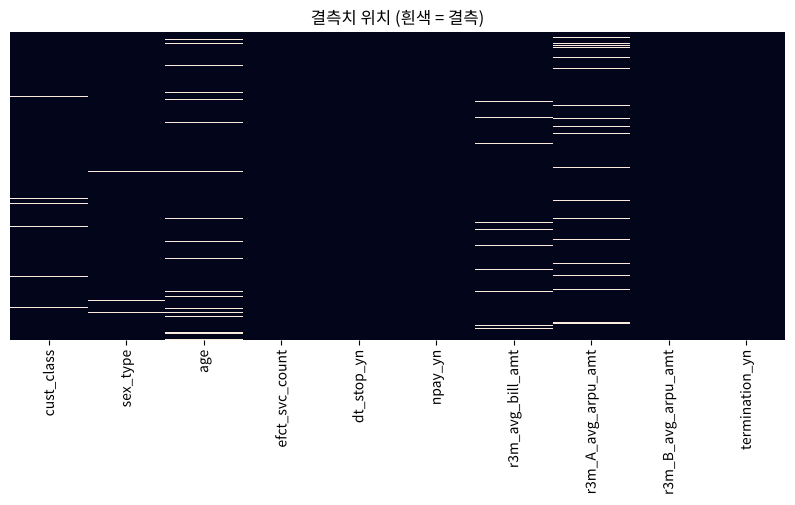

In [10]:
# 결측치 위치 시각화
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title('결측치 위치 (흰색 = 결측)')
plt.show()

---
## 3. 결측치 처리 방법 선택 기준

| 상황 | 처리 방법 |
|---|---|
| 결측 행이 전체의 소수 (예: 5% 미만) | 행 삭제 `dropna()` |
| 특정 컬럼의 결측이 대부분 (예: 50% 이상) | 컬럼 삭제 `drop(columns=...)` |
| 수치형, 분포가 대칭 | 평균 대체 `fillna(mean)` |
| 수치형, 이상치가 있거나 치우침 | **중앙값** 대체 `fillna(median)` |
| 범주형 | **최빈값** 대체 `fillna(mode()[0])` 또는 'Unknown' 같은 새 범주 |
| 시계열 | 앞/뒤 값으로 채우기 `ffill()`/`bfill()`, 보간 `interpolate()` |

> ⚠️ 시험에서는 처리 방법이 **문항 가이드에 정확히 지정**됩니다. 가이드대로만 처리하세요.

---
## 4. 결측치 삭제: `dropna`

In [11]:
print("원본:", df.shape)
print("결측 있는 행 모두 삭제:", df.dropna().shape)
print("모든 값이 결측인 행만 삭제:", df.dropna(how='all').shape)
print("age가 결측인 행만 삭제:", df.dropna(subset=['age']).shape)
print("결측 아닌 값이 9개 이상인 행만 유지:", df.dropna(thresh=9).shape)

원본: (9930, 10)
결측 있는 행 모두 삭제: (8540, 10)
모든 값이 결측인 행만 삭제: (9930, 10)
age가 결측인 행만 삭제: (9411, 10)
결측 아닌 값이 9개 이상인 행만 유지: (9840, 10)


In [12]:
# 결측이 있는 컬럼 자체를 삭제
df.dropna(axis=1).columns

Index(['efct_svc_count', 'dt_stop_yn', 'npay_yn', 'r3m_B_avg_arpu_amt',
       'termination_yn'],
      dtype='object')

---
## 5. 결측치 대체: `fillna`

> ⚠️ pandas 최신 버전에서는 `df['col'].fillna(값, inplace=True)` 가 경고를 내거나 원본에 반영되지 않을 수 있습니다.
> **`df['col'] = df['col'].fillna(값)`** 처럼 다시 할당하는 방식을 권장합니다.

In [13]:
df_fill = df.copy()       # 원본 보존을 위해 복사본에서 작업

# 수치형: 중앙값
age_median = df_fill['age'].median()
df_fill['age'] = df_fill['age'].fillna(age_median)

# 수치형: 평균
df_fill['r3m_A_avg_arpu_amt'] = df_fill['r3m_A_avg_arpu_amt'].fillna(df_fill['r3m_A_avg_arpu_amt'].mean())

# 범주형: 최빈값 (mode()는 Series를 반환하므로 [0])
df_fill['cust_class'] = df_fill['cust_class'].fillna(df_fill['cust_class'].mode()[0])

# 범주형: 새로운 범주
df_fill['sex_type'] = df_fill['sex_type'].fillna('Unknown')

df_fill.isnull().sum()

cust_class              0
sex_type                0
age                     0
efct_svc_count          0
dt_stop_yn              0
npay_yn                 0
r3m_avg_bill_amt      309
r3m_A_avg_arpu_amt      0
r3m_B_avg_arpu_amt      0
termination_yn          0
dtype: int64

In [14]:
# 그룹별 통계로 채우기: 고객 등급별 청구액 중앙값으로 대체
df_fill['r3m_avg_bill_amt'] = df_fill['r3m_avg_bill_amt'].fillna(
    df_fill.groupby('cust_class')['r3m_avg_bill_amt'].transform('median'))
df_fill.isnull().sum().sum()

np.int64(0)

In [15]:
# 여러 컬럼을 딕셔너리로 한 번에
df.fillna({'age': 0, 'sex_type': 'Unknown'}).isnull().sum()

cust_class            150
sex_type                0
age                     0
efct_svc_count          0
dt_stop_yn              0
npay_yn                 0
r3m_avg_bill_amt      309
r3m_A_avg_arpu_amt    410
r3m_B_avg_arpu_amt      0
termination_yn          0
dtype: int64

In [16]:
# 앞/뒤 값으로 채우기, 선형 보간 (시계열 데이터에서 주로 사용 → 16번 미세먼지 실습)
s = pd.Series([10, np.nan, np.nan, 40, np.nan])
pd.DataFrame({'원본': s, 'ffill': s.ffill(), 'bfill': s.bfill(), 'interpolate': s.interpolate()})

,원본,ffill,bfill,interpolate
0,10.0,10.0,10.0,10.0
1,NaN,10.0,40.0,20.0
2,NaN,10.0,40.0,30.0
3,40.0,40.0,40.0,40.0
4,NaN,40.0,NaN,40.0


---
## 6. scikit-learn `SimpleImputer`

학습 데이터에서 계산한 대체값을 검증/테스트 데이터에도 **같은 값으로** 적용할 때 유용합니다.

In [17]:
from sklearn.impute import SimpleImputer

num_cols = ['age', 'r3m_avg_bill_amt', 'r3m_A_avg_arpu_amt']
imp = SimpleImputer(strategy='median')          # 'mean', 'median', 'most_frequent', 'constant'
df_imp = df.copy()
df_imp[num_cols] = imp.fit_transform(df_imp[num_cols])
print(imp.statistics_)
df_imp[num_cols].isnull().sum()

[   45.   19606.24 16363.54]


age                   0
r3m_avg_bill_amt      0
r3m_A_avg_arpu_amt    0
dtype: int64

---
## 7. 탐색적 데이터 분석(EDA) 맛보기

결측치를 처리했다면, 타깃(해지 여부)과 각 변수의 관계를 살펴봅니다. (시각화는 08~09번에서 자세히)

In [18]:
df_fill['termination_yn'].value_counts(normalize=True)

termination_yn
N    0.817321
Y    0.182679
Name: proportion, dtype: float64

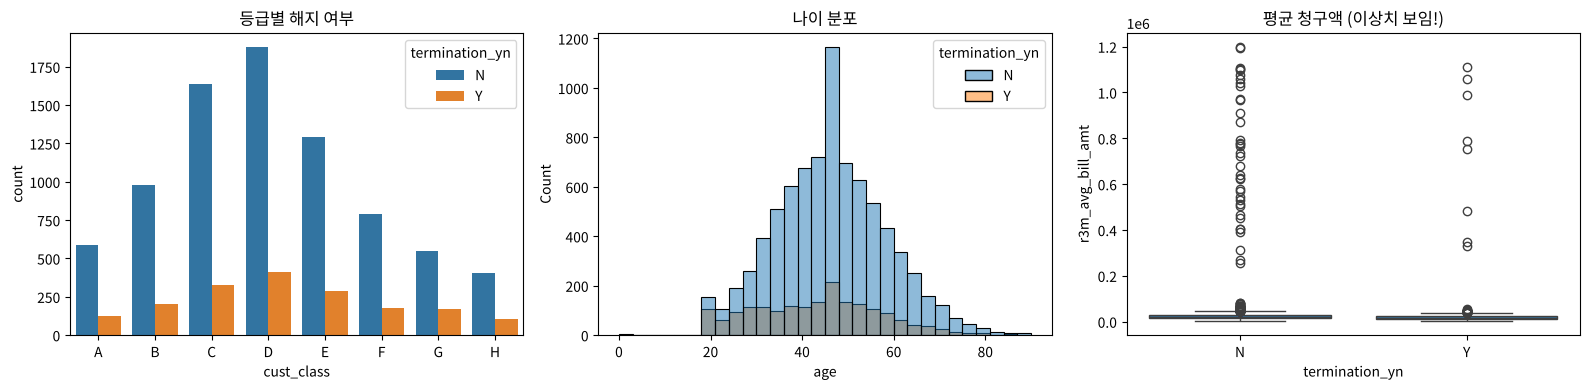

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df_fill, x='cust_class', hue='termination_yn', order=sorted(df_fill['cust_class'].unique()), ax=axes[0])
sns.histplot(data=df_fill[df_fill['age'] < 100], x='age', hue='termination_yn', bins=30, ax=axes[1])
sns.boxplot(data=df_fill, x='termination_yn', y='r3m_avg_bill_amt', ax=axes[2])
axes[0].set_title('등급별 해지 여부')
axes[1].set_title('나이 분포')
axes[2].set_title('평균 청구액 (이상치 보임!)')
plt.tight_layout()
plt.show()

In [20]:
df_fill.groupby('dt_stop_yn')['termination_yn'].value_counts(normalize=True).unstack()

termination_yn,N,Y
dt_stop_yn,,
N,0.863881,0.136119
Y,0.295203,0.704797


> 📌 오른쪽 boxplot에서 위쪽으로 동떨어진 점들이 **이상치**입니다. 다음 노트북(07)에서 처리합니다.

---
## ✏️ 연습문제

In [21]:
data = pd.read_csv('sc_cust_info_txn_v1.5.csv')

**문제 1.** `data`의 전체 결측치 개수를 `답안1` 변수에 저장하세요.

In [22]:
# 여기에 답안코드를 작성하고 실행하세요.

**문제 2.** 결측 비율이 가장 높은 컬럼명을 `답안2` 변수에 저장하세요.

In [23]:
# 여기에 답안코드를 작성하고 실행하세요.

**문제 3.** 아래 가이드에 따라 결측치를 처리하고 결과를 `data_na`에 저장하세요.
- `cust_class`, `sex_type` 이 결측인 행은 삭제
- `age` 는 중앙값으로 대체
- `r3m_avg_bill_amt`, `r3m_A_avg_arpu_amt` 는 평균값으로 대체
- 처리 후 결측치가 없는지 확인하고, `data_na`의 행 개수를 `답안3` 변수에 저장

In [24]:
# 여기에 답안코드를 작성하고 실행하세요.

**문제 4.** 아래 코드의 빈칸을 채우고 실행하세요. 빈칸 내용을 `답안4_1`, `답안4_2` 변수에 저장하세요.
```python
print('결측치 처리 전\n', data.< blank4-1 >().sum())
data_drop = data.< blank4-2 >()
print('결측치 처리 후\n', data_drop.< blank4-1 >().sum())
```

In [25]:
# 아래 코드의 빈칸을 채우고 실행하세요.

---
## ✅ 정답 및 해설

In [26]:
# 문제 1
답안1 = data.isnull().sum().sum()
print(답안1)

# 문제 2
답안2 = data.isnull().mean().idxmax()      # idxmax: 최댓값의 인덱스(=컬럼명)
print(답안2)

1483
age


In [27]:
# 문제 3
data_na = data.dropna(subset=['cust_class', 'sex_type']).copy()
data_na['age'] = data_na['age'].fillna(data_na['age'].median())
for col in ['r3m_avg_bill_amt', 'r3m_A_avg_arpu_amt']:
    data_na[col] = data_na[col].fillna(data_na[col].mean())
print(data_na.isnull().sum())
답안3 = len(data_na)
print('답안3 =', 답안3)

cust_class            0
sex_type              0
age                   0
efct_svc_count        0
dt_stop_yn            0
npay_yn               0
r3m_avg_bill_amt      0
r3m_A_avg_arpu_amt    0
r3m_B_avg_arpu_amt    0
termination_yn        0
dtype: int64
답안3 = 9687


In [28]:
# 문제 4
print('결측치 처리 전\n', data.isnull().sum())
data_drop = data.dropna()
print('결측치 처리 후\n', data_drop.isnull().sum())
답안4_1 = 'isnull'
답안4_2 = 'dropna'

결측치 처리 전
 cust_class            150
sex_type               95
age                   519
efct_svc_count          0
dt_stop_yn              0
npay_yn                 0
r3m_avg_bill_amt      309
r3m_A_avg_arpu_amt    410
r3m_B_avg_arpu_amt      0
termination_yn          0
dtype: int64
결측치 처리 후
 cust_class            0
sex_type              0
age                   0
efct_svc_count        0
dt_stop_yn            0
npay_yn               0
r3m_avg_bill_amt      0
r3m_A_avg_arpu_amt    0
r3m_B_avg_arpu_amt    0
termination_yn        0
dtype: int64
